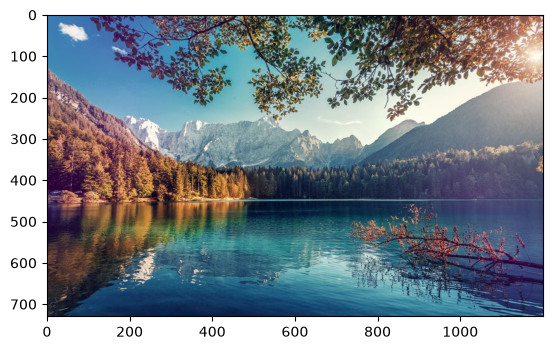

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open('image.png')
plt.imshow(img)

In [12]:
from urllib import request
import os

filenames = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz"
]

folder = 'data_fashion_mnist/'
base_url = "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/"

# Tạo thư mục nếu chưa tồn tại
os.makedirs(folder, exist_ok=True)

for name in filenames:
    print("Downloading " + name + "...")

    # Lưu vào folder data_fashion_mnist
    request.urlretrieve(base_url + name, folder + name)

print("Download complete.")

Download complete.


In [1]:
import numpy as np
import gzip

with gzip.open('data_fashion_mnist/train-images-idx3-ubyte.gz', 'rb') as f:
    X_train = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28 * 28)

with gzip.open('data_fashion_mnist/t10k-images-idx3-ubyte.gz', 'rb') as f:
    X_test = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28 * 28)

with gzip.open('data_fashion_mnist/train-labels-idx1-ubyte.gz', 'rb') as f:
    y_train = np.frombuffer(f.read(), np.uint8, offset=8)

with gzip.open('data_fashion_mnist/t10k-labels-idx1-ubyte.gz', 'rb') as f:
    y_test = np.frombuffer(f.read(), np.uint8, offset=8)


In [2]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 784)
(10000, 784)
(60000,)
(10000,)


In [3]:
print(type(X_train))
print(type(y_train))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [5]:
from PIL import Image
for i in range(10):
    im = Image.fromarray(X_train[i].reshape(28, 28))
    im.save('images/image_' + str(i) + ".png")

In [6]:
y_train[0]

np.uint8(9)

Using Pytorch

In [11]:
from torchvision.datasets import FashionMNIST
trainset = FashionMNIST(root = 'data', 
                        train = True,
                        download='True')
img, label = trainset[0]
print(type(img))
print(f'Label: {label}')

<class 'PIL.Image.Image'>
Label: 9


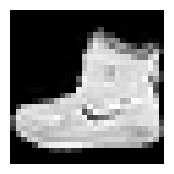

In [12]:
import matplotlib.pyplot as plt
img, _ = trainset[0]
plt.figure(figsize=(2, 2))
plt.imshow(img, cmap = 'gray')
plt.axis('off')
plt.show()

In [16]:
# Convert to Tensor
from torch.utils.data import DataLoader
from torchvision import transforms

transform = transforms.Compose([transforms.ToTensor()])
trainset = FashionMNIST(root = 'data', train = True, download = True, transform = transform)
img, label = trainset[0]
print(type(img), label)

print(img.shape)

<class 'torch.Tensor'> 9
torch.Size([1, 28, 28])


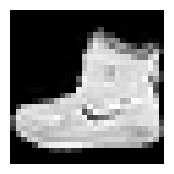

In [17]:
img, _ = trainset[0]
np_img = img.numpy()
np_img = np.transpose(np_img, (1, 2, 0))
plt.figure(figsize=(2, 2))
plt.imshow(np_img, cmap = 'gray')
plt.axis('off')
plt.show()

In [21]:
transform = transforms.Compose([transforms.ToTensor()])
trainset = FashionMNIST(root = 'data',
                        train = True, 
                        download = True,
                        transform = transform)

trainloader = DataLoader(
    trainset,
    batch_size=1024,
    num_workers = 6, # So luong chay song song
    shuffle = True
)

print(len(trainloader))
print(type(trainloader))

59
<class 'torch.utils.data.dataloader.DataLoader'>


In [29]:
for d in trainloader:
    images, labels = d
    print(images.shape)
    print(labels.shape)
    break

torch.Size([1024, 1, 28, 28])
torch.Size([1024])


In [31]:
for i, (inputs, labels) in enumerate(trainloader, 1):
    print(f'Batch index {i} -- {inputs.shape} -- {labels.shape}')

Batch index 1 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 2 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 3 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 4 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 5 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 6 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 7 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 8 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 9 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 10 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 11 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 12 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 13 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 14 -- torch.Size([1024, 1, 28, 28]) -- torch.Size([1024])
Batch index 15 -- torch.Size(

In [32]:
import torch
X = inputs
print(X.shape)

torch.Size([608, 1, 28, 28])


In [33]:
flatten_layer = torch.nn.Flatten()
X_flatten = flatten_layer(X)
print(X_flatten.shape)

torch.Size([608, 784])


In [34]:
linear_layer = torch.nn.Linear(784, 20)

logits = linear_layer(X_flatten)
print(logits.shape)

torch.Size([608, 20])
